#Data

## Data folder

In this step we retrieve the data from the folder where it is located

In [ ]:
# Connect Google Colab to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

path = '/content/drive/MyDrive/ML_proj/Projeto/'

Mounted at /content/drive


## Libraries

Install and import the libraries

### Install

In [ ]:
# Step 1 - Install pandas using the pip install command
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn

### Import

In [ ]:
# Step 2 - Import relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Use the command '%matplotlib inline' after importing matplotlib to guarantee that the plots are on the notebook


#set seaborn as default style for visualizations
sns.set()

## File access

Read the excel file provided

In [ ]:
world_citizens = pd.read_excel(path + 'Data/world_citizens.xlsx')

#as a good practice, we avoided working on the dataset imported and created a copy instead
wd_ct = world_citizens.copy()
wd_ct.head(5)

,avg_monthly_entertainment_expenses,avg_weekly_exercise_hours,citizen_id,city,country,date_of_birth,eco_consciousness_score,education_level,environmental_awareness_rating,financial_wellness_index,...,investment_portfolio_value,investments_risk_appetite,investments_risk_tolerance,last_year_charity_donations,marital_status,name,social_media_influence_score,stress_management_score,title,well_being_level
0,8.8730,0.0000,1,Palmas,Brazil,1982-02-15,0.0000,5.5454,0.5576,264.3460,...,0.1313,6.7866,22.9550,0.0000,,Mafalda,2.6469,3.0448,Ms.,3.9098
1,10.9348,0.1298,2,Taupo,New Zealand,1989-11-07,0.0000,4.9150,0.5998,209.9720,...,0.0000,7.2836,17.0296,0.0000,,Olive,2.1466,1.8311,Mrs.,4.4571
2,29.9206,0.1129,3,Nauen,Germany,1972-03-13,0.0000,9.4307,0.6302,21.6053,...,5.1244,4.1800,3.9274,0.0000,,Esther,10.2169,3.9353,Ms.,4.3552
3,36.0014,0.0419,4,Kusel,Germany,1982-04-28,0.0134,8.5129,0.6066,87.0453,...,6.1273,7.1364,6.0943,0.1132,,Ramon,4.9333,NaN,Mr.,5.7737
4,6.0075,1.2697,5,Rize,Turkey,1996-09-05,0.0000,6.0902,1.1385,95.4032,...,6.2140,4.3797,3.1951,0.0000,,Koray,8.2687,2.2987,Mr.,2.5274


# Visuals and Analysis of the variable

In [ ]:
wd_ct.shape

(8327, 22)

## Values for city

See all possible values for the variable city

### 3733 Different cities + 9 missing values

In [ ]:
a = 1
for i in wd_ct['city'].unique():
  print(f'{a}: {i}')
  a += 1

1: Palmas
2: Taupo
3: Nauen
4: Kusel
5: Rize
6: Ú©Ø±Ù…Ø§Ù†Ø´Ø§Ù‡
7: Rheeze
8: Chelsea
9: Carrick-on-Suir
10: Cardiff
11: Roscommon
12: Tramore
13: Manchester
14: Koudum
15: Bhiwandi
16: Schwandorf
17: Ú¯Ù„Ø³ØªØ§Ù†
18: Reims
19: Vranje
20: Pallavaram
21: Marrum
22: Kiiminki
23: Ã„Ã¤nekoski
24: Bobrovicya
25: JÃ¤mijÃ¤rvi
26: PoÃ§os de Caldas
27: Noviy Rozdil
28: SchÃ¶nebeck (Elbe)
29: Tecumseh
30: Masterton
31: Termunten
32: Mulhouse
33: BrÃ¸ndby Strand
34: Kempele
35: Sotkamo
36: Angerlo
37: Nowra
38: Sidney
39: LuÄ_x008d_ani
40: Tatarbunari
41: VÃ¥re
42: Torrente
43: Lieberose
44: Nelson
45: Grenoble
46: Warrnambool
47: Garmerwolde
48: Dorchester
49: Eernewoude
50: PÃ¶ytyÃ¤
51: Renbygda
52: Porirua
53: Kristiansand
54: VitÃ³ria
55: Dibrugarh
56: Inverness
57: La CoruÃ±a
58: BeitostÃ¸len
59: Amaravati
60: Celbridge
61: ChÃ¢tel-Saint-Denis
62: Yozgat
63: Vitoria
64: Eriz
65: Stoevring
66: Kalgoorlie
67: Duggingen
68: MÃ³stoles
69: Vang
70: Boulogne-Billancourt
71: Mogi das Cruzes
72: Ris

In [ ]:
wd_ct['city'].isna().sum()

0

In [ ]:
#From the excel we concluded that the missing values in this collumn where represented as '?'
wd_ct['city'].isin(['?']).sum()

9

## Values for country

In [ ]:
a = 1
for i in wd_ct['country'].unique():
  print(f'{a}: {i}')
  a += 1

1: Brazil
2: New Zealand
3: Germany
4: Turkey
5: Iran
6: Netherlands
7: Canada
8: Ireland
9: United Kingdom
10: India
11: France
12: Serbia
13: Finland
14: Ukraine
15: Denmark
16: Australia
17: Norway
18: Spain
19: Switzerland
20: Mexico
21: United States
22:   


In [ ]:
wd_ct['country'].isna().sum()

0

The program considers empty answers as an answer and not a missing value, we need to change this somehow

## Distribution among countries


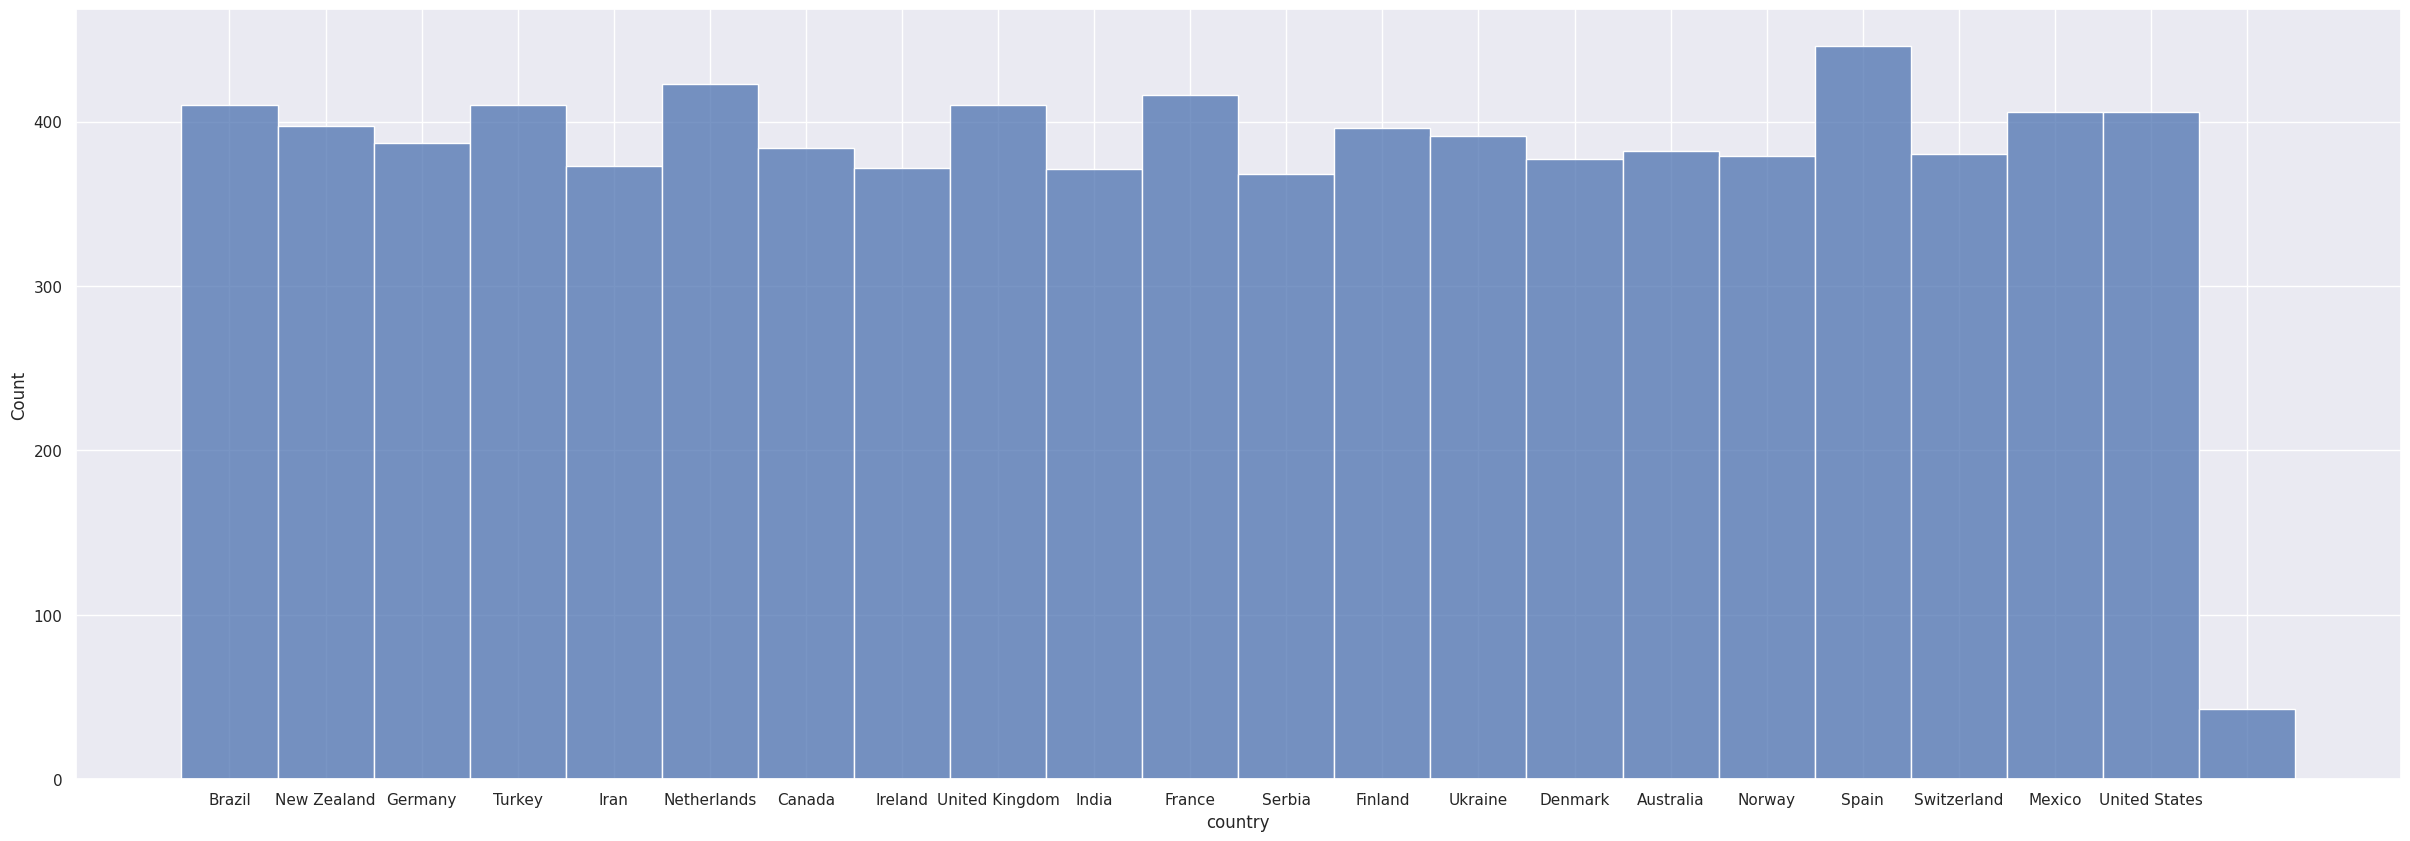

In [ ]:
plt.figure(figsize=(30, 10))
sns.histplot(wd_ct['country'])
plt.show()

# Sugestions for these collumns

## First: Drop cities

Why:
1. It adds uneeded complexity, might cause an overfitting of the model, contains non coherent values, among others.
2. Even though it could be a plus to be able to locate more happy cities, the quality of the data provided sure is questionable, being contra-produtive to include this variable



In [ ]:
wd_ct = wd_ct.drop('city', axis=1)

We will still keep a diferent data set with it, which will be subjected to everything the other one is, for comparision reasons

## Second: Replace the blank spaces in country by missing value

Why:
1.   It helps the algorithms to be more accurate
2.   That way we can replace later the values using a predictive algorithm



In [ ]:
wd_ct['country'] = wd_ct['country'].replace('  ', np.nan)
wd_ct['country'].isna().sum()

43

## Third: Use an inputation method that considers all collumns of the data set to input these 43 missing values (KNN or a decision tree)